# 🎯 Customer Segmentation & Churn Prediction ML Pipeline
### End-to-End Machine Learning Portfolio Project: RFM Clustering & Ensemble Churn Classification

---

## 📌 Executive Summary & Business Context
Customer churn directly impacts business Lifetime Value (LTV) and Customer Acquisition Cost (CAC) payback periods. In modern subscription and e-commerce models, acquiring a new customer is **5x to 7x more expensive** than retaining an existing one.

### Objectives:
1. **Behavioral Segmentation:** Compute **Recency, Frequency, and Monetary (RFM)** features to segment customers into actionable marketing personas (*Champions*, *Loyal Customers*, *At-Risk*, *Hibernating*) using **K-Means Clustering** with **Elbow** and **Silhouette** validation.
2. **Predictive Churn Modeling:** Predict customer churn using supervised classification algorithms (**Logistic Regression**, **Random Forest**, **Gradient Boosting**), addressing class imbalance and evaluating models via **F1-Score** and **ROC-AUC**.
3. **Model Explainability & Retention Playbook:** Identify the primary drivers of churn to formulate targeted, high-ROI retention interventions.

## 1. ⚙️ Environment Setup & Library Imports

In [1]:
import os
import sys
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML & Evaluation Libraries
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix, roc_curve, roc_auc_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Visual configurations
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_context('notebook', font_scale=1.1)
print('Libraries successfully imported.')

Libraries successfully imported.


## 2. 📊 Data Ingestion & Initial Inspection
We load the transaction-level records from `../data/customer_transactions.csv`.

In [2]:
data_path = os.path.join('..', 'data', 'customer_transactions.csv')
df = pd.read_csv(data_path)
df['invoice_date'] = pd.to_datetime(df['invoice_date'])

print(f'Total Transaction Rows: {len(df):,}')
print(f'Unique Customer IDs  : {df["customer_id"].nunique():,}')
print(f'Transaction Window    : {df["invoice_date"].min().strftime("%Y-%m-%d")} to {df["invoice_date"].max().strftime("%Y-%m-%d")}')
df.head()

Total Transaction Rows: 15,000
Unique Customer IDs  : 2,500
Transaction Window    : 2024-11-11 to 2026-10-30


,customer_id,invoice_date,order_amount,tenure_months,support_tickets,contract_type,churned
0,CUST_02125,2024-11-11 02:23:21,26.47,59,1,Two-year,0
1,CUST_01337,2024-11-11 08:14:27,25.71,54,2,Month-to-month,1
2,CUST_01482,2024-11-11 08:36:58,53.60,33,2,Month-to-month,1
3,CUST_00037,2024-11-11 16:05:24,165.95,27,2,Month-to-month,1
4,CUST_01814,2024-11-11 18:53:30,51.96,42,3,Month-to-month,1


## 3. 🔍 Exploratory Data Analysis (EDA)
Examining customer churn rates across contract types, support tickets, and customer tenure.

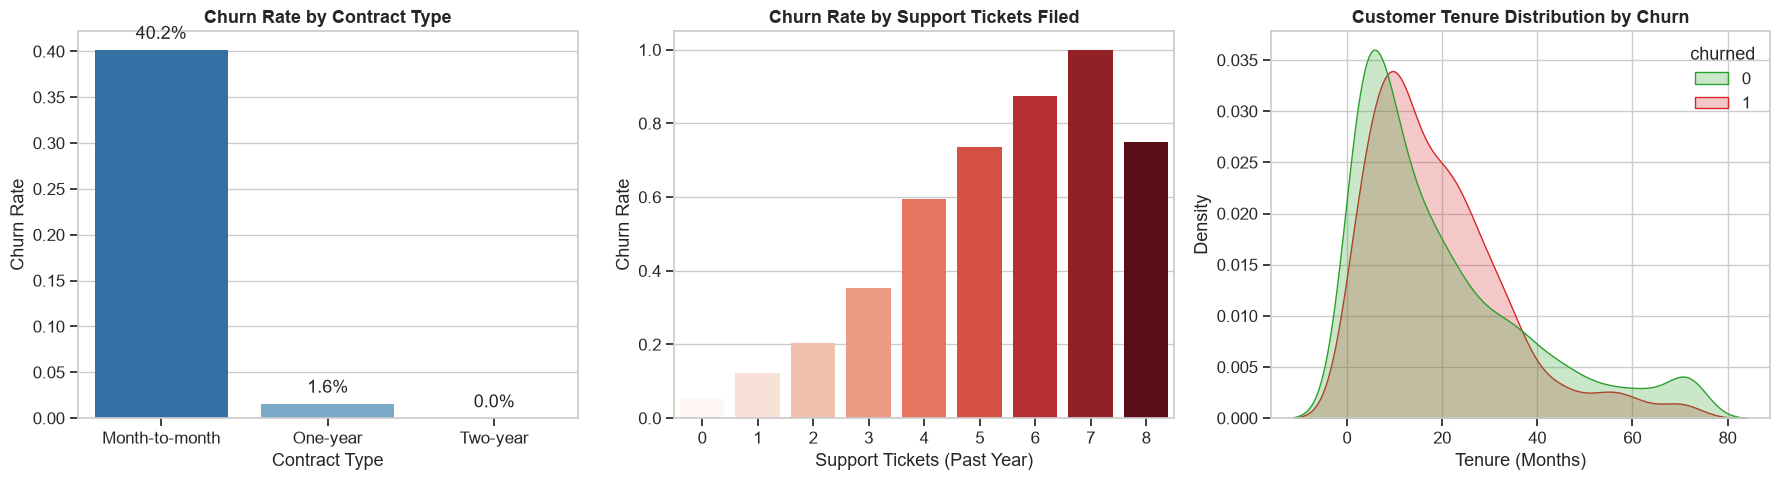

In [3]:
# Collapse transactions to unique customer-level records for demographic EDA
cust_eda = df.groupby('customer_id').agg({
    'tenure_months': 'first',
    'support_tickets': 'first',
    'contract_type': 'first',
    'churned': 'first',
    'order_amount': ['count', 'sum', 'mean']
}).reset_index()

cust_eda.columns = ['customer_id', 'tenure_months', 'support_tickets', 'contract_type', 'churned', 'order_count', 'total_spend', 'avg_order_value']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Churn by Contract Type
contract_churn = cust_eda.groupby('contract_type')['churned'].mean().reset_index()
sns.barplot(data=contract_churn, x='contract_type', y='churned', palette='Blues_r', ax=axes[0], hue='contract_type', legend=False)
axes[0].set_title('Churn Rate by Contract Type', fontweight='bold')
axes[0].set_ylabel('Churn Rate')
axes[0].set_xlabel('Contract Type')
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.1%}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

# 2. Churn by Support Tickets
ticket_churn = cust_eda.groupby('support_tickets')['churned'].agg(['mean', 'count']).reset_index()
sns.barplot(data=ticket_churn, x='support_tickets', y='mean', palette='Reds', ax=axes[1], hue='support_tickets', legend=False)
axes[1].set_title('Churn Rate by Support Tickets Filed', fontweight='bold')
axes[1].set_ylabel('Churn Rate')
axes[1].set_xlabel('Support Tickets (Past Year)')

# 3. Tenure Distribution by Churn Status
sns.kdeplot(data=cust_eda, x='tenure_months', hue='churned', common_norm=False, fill=True, palette={0: '#2ca02c', 1: '#d62728'}, ax=axes[2])
axes[2].set_title('Customer Tenure Distribution by Churn', fontweight='bold')
axes[2].set_xlabel('Tenure (Months)')

plt.tight_layout()
plt.show()

### 💡 Key EDA Findings:
1. **Contract Type:** Month-to-month customers experience dramatically higher churn rates compared to those on 1-year and 2-year commitments.
2. **Support Interactions:** Churn risk escalates sharply as support tickets exceed 3-4 incidents, pinpointing customer frustration as a primary catalyst.
3. **Tenure Loyalty:** The highest density of churn occurs during the first 6-12 months of customer onboarding.

## 4. 🧮 RFM Feature Engineering & Transformation
We engineer three behavioral vectors per customer:
- **Recency ($R$):** Days elapsed since the customer's most recent purchase.
- **Frequency ($F$):** Total count of completed transactions.
- **Monetary Value ($M$):** Aggregate gross spend.

In [4]:
# Set reference date: max date + 1 day
ref_date = df['invoice_date'].max() + pd.Timedelta(days=1)

rfm = df.groupby('customer_id').agg(
    recency=('invoice_date', lambda x: (ref_date - x.max()).days),
    frequency=('invoice_date', 'count'),
    monetary=('order_amount', 'sum'),
    avg_order_value=('order_amount', 'mean'),
    tenure_months=('tenure_months', 'first'),
    support_tickets=('support_tickets', 'first'),
    contract_type=('contract_type', 'first'),
    churned=('churned', 'first'),
).reset_index()

rfm[['recency', 'frequency', 'monetary', 'avg_order_value']].describe()

,recency,frequency,monetary,avg_order_value
count,2500.000000,2500.00000,2500.000000,2500.000000
mean,86.909200,6.00000,365.468504,60.443476
std,113.074174,4.18452,282.460920,23.802106
min,1.000000,1.00000,9.990000,9.990000
25%,13.000000,3.00000,160.350000,45.495208
50%,44.000000,5.00000,298.370000,56.951852
75%,113.000000,8.00000,489.975000,70.474432
max,704.000000,30.00000,2304.020000,389.120000


### Mitigating Skewness with Log Transformation
K-Means is sensitive to extreme outliers and skewed features. Applying $\log(1 + x)$ balances feature variance before standardization.

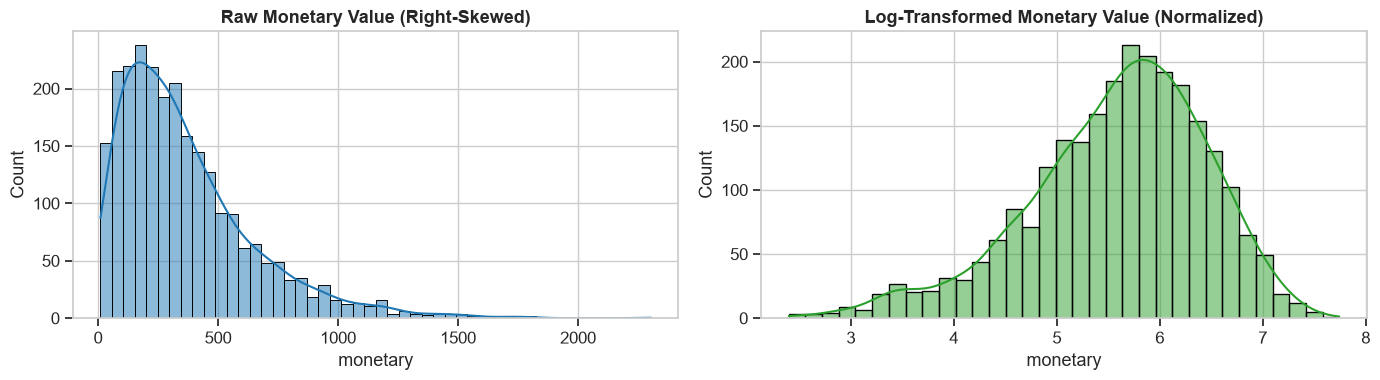

In [5]:
rfm_raw = rfm[['recency', 'frequency', 'monetary']]
rfm_log = np.log1p(rfm_raw)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(rfm['monetary'], kde=True, ax=axes[0], color='#1f77b4')
axes[0].set_title('Raw Monetary Value (Right-Skewed)', fontweight='bold')

sns.histplot(rfm_log['monetary'], kde=True, ax=axes[1], color='#2ca02c')
axes[1].set_title('Log-Transformed Monetary Value (Normalized)', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. 🎯 Optimal Cluster Determination & K-Means Segmentation
Evaluating $k \in [2, 7]$ using **Within-Cluster Sum of Squares (Inertia)** and **Silhouette Score**.

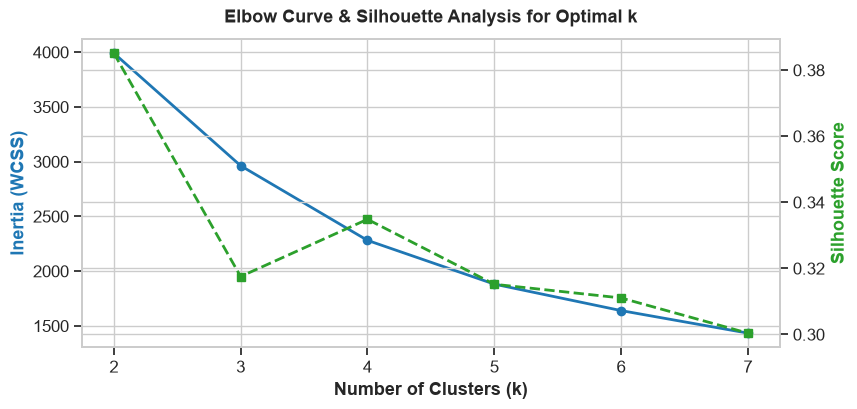

In [6]:
k_range = range(2, 8)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled, km.labels_))

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(k_range, inertias, marker='o', color='#1f77b4', linewidth=2, label='Inertia (Elbow)')
ax1.set_xlabel('Number of Clusters (k)', fontweight='bold')
ax1.set_ylabel('Inertia (WCSS)', color='#1f77b4', fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(k_range, sil_scores, marker='s', color='#2ca02c', linewidth=2, linestyle='--', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='#2ca02c', fontweight='bold')
plt.title('Elbow Curve & Silhouette Analysis for Optimal k', fontweight='bold', pad=12)
plt.show()

### Assigning Strategic Business Personas ($k=4$)
We fit K-Means with $k=4$ and map clusters based on relative RFM ranks:
- **Champions:** Low Recency, High Frequency, High Spend
- **Loyal Customers:** Moderate Recency, Steady Frequency & Spend
- **At-Risk:** High Recency (inactive), High/Moderate Historical Spend
- **Hibernating:** Long Inactivity, Low Order Frequency & Spend

In [7]:
kmeans = KMeans(n_clusters=4, init='k-means++', n_init=15, random_state=42)
rfm['cluster'] = kmeans.fit_predict(rfm_scaled)

# Map clusters by engagement scores
summary = rfm.groupby('cluster').agg(
    med_r=('recency', 'median'),
    med_f=('frequency', 'median'),
    med_m=('monetary', 'median'),
)

scores = {c: (summary.loc[c, 'med_f'] * 1.5 + np.log1p(summary.loc[c, 'med_m']) * 2.0) - (summary.loc[c, 'med_r'] * 0.1) for c in summary.index}
ranked = sorted(scores.keys(), key=lambda c: scores[c], reverse=True)

label_map = {
    ranked[0]: 'Champions',
    ranked[1]: 'Loyal Customers',
}
rem1, rem2 = ranked[2], ranked[3]
if summary.loc[rem1, 'med_m'] >= summary.loc[rem2, 'med_m']:
    label_map[rem1] = 'At-Risk'
    label_map[rem2] = 'Hibernating'
else:
    label_map[rem2] = 'At-Risk'
    label_map[rem1] = 'Hibernating'

rfm['cluster_label'] = rfm['cluster'].map(label_map)

# Segment Profile Summary
segment_profile = rfm.groupby('cluster_label').agg(
    Customer_Count=('customer_id', 'count'),
    Avg_Recency_Days=('recency', 'mean'),
    Median_Frequency=('frequency', 'median'),
    Avg_Monetary_Spend=('monetary', 'mean'),
    Churn_Rate=('churned', 'mean')
).reset_index()

segment_profile['Churn_Rate'] = segment_profile['Churn_Rate'].apply(lambda x: f'{x:.1%}')
segment_profile['Avg_Monetary_Spend'] = segment_profile['Avg_Monetary_Spend'].apply(lambda x: f'${x:,.2f}')
segment_profile

,cluster_label,Customer_Count,Avg_Recency_Days,Median_Frequency,Avg_Monetary_Spend,Churn_Rate
0,At-Risk,831,109.808664,5.0,$353.11,29.2%
1,Champions,611,20.155483,11.0,$727.98,3.8%
2,Hibernating,547,194.700183,2.0,$96.59,42.8%
3,Loyal Customers,511,14.101761,4.0,$239.94,11.7%


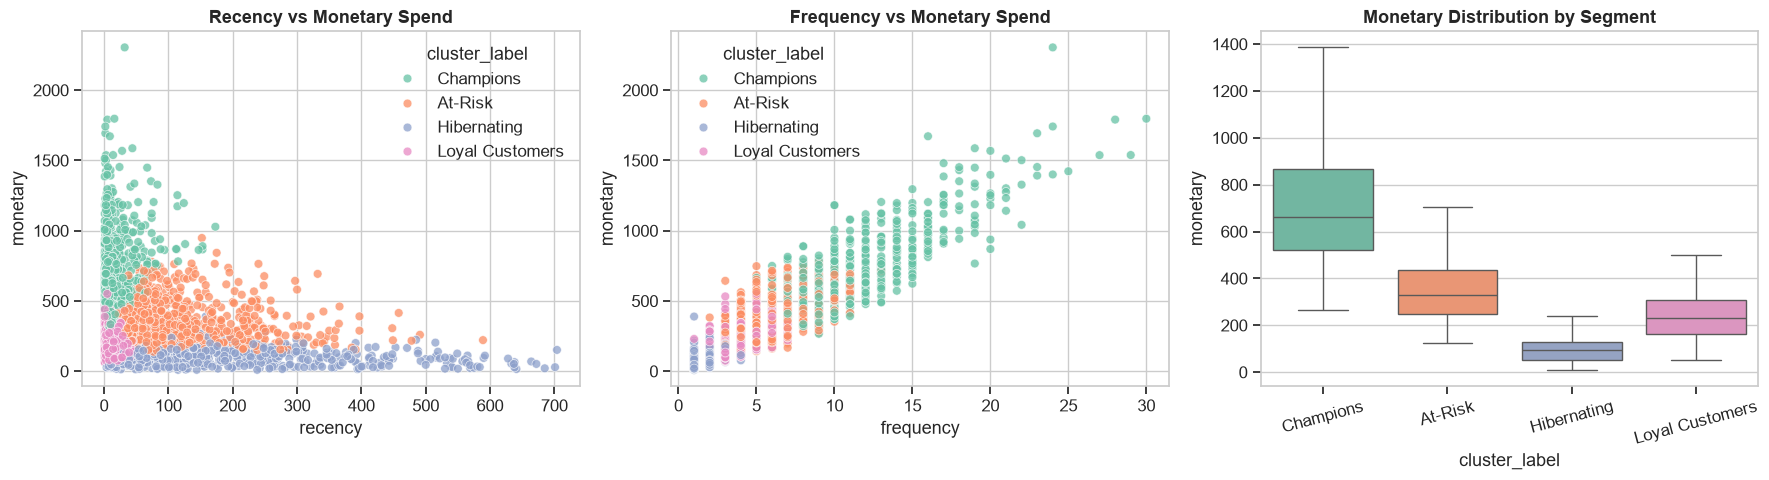

In [8]:
# Multi-panel cluster visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette = sns.color_palette('Set2', 4)

sns.scatterplot(data=rfm, x='recency', y='monetary', hue='cluster_label', palette=palette, s=40, alpha=0.75, ax=axes[0])
axes[0].set_title('Recency vs Monetary Spend', fontweight='bold')

sns.scatterplot(data=rfm, x='frequency', y='monetary', hue='cluster_label', palette=palette, s=40, alpha=0.75, ax=axes[1])
axes[1].set_title('Frequency vs Monetary Spend', fontweight='bold')

sns.boxplot(data=rfm, x='cluster_label', y='monetary', hue='cluster_label', palette=palette, legend=False, showfliers=False, ax=axes[2])
axes[2].set_title('Monetary Distribution by Segment', fontweight='bold')
axes[2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 6. 🚀 Predictive Churn Classification
We integrate the cluster segments with behavioral metrics, handle class imbalance, and benchmark 3 scikit-learn classifiers:
1. **Logistic Regression** (baseline, balanced weights, interpretable log-odds)
2. **Random Forest Classifier** (non-linear ensemble, balanced weights)
3. **Gradient Boosting Classifier** (boosted trees)

Evaluated using **Stratified 5-Fold Cross-Validation**, **F1-Score**, and **ROC-AUC**.

In [9]:
# One-hot encode categoricals
cat_cols = ['contract_type', 'cluster_label']
num_cols = ['recency', 'frequency', 'monetary', 'avg_order_value', 'tenure_months', 'support_tickets']

X_cats = pd.get_dummies(rfm[cat_cols], prefix=cat_cols, drop_first=False, dtype=float)
X = pd.concat([rfm[num_cols], X_cats], axis=1)
y = rfm['churned'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Train shape: {X_train.shape}, Test shape: {X_test.shape}')
print(f'Train Churn Rate: {y_train.mean():.2%}, Test Churn Rate: {y_test.mean():.2%}')

Train shape: (1875, 13), Test shape: (625, 13)
Train Churn Rate: 22.40%, Test Churn Rate: 22.40%


In [10]:
models = {
    'Logistic Regression': (LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42), True),
    'Random Forest': (RandomForestClassifier(n_estimators=150, max_depth=7, class_weight='balanced', random_state=42, n_jobs=-1), False),
    'Gradient Boosting': (GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=4, random_state=42), False),
}

results = []
test_probs = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, (clf, use_scaled) in models.items():
    X_tr = X_train_scaled if use_scaled else X_train.values
    X_te = X_test_scaled if use_scaled else X_test.values
    
    cv_roc = cross_val_score(clf, X_tr, y_train, cv=cv, scoring='roc_auc')
    clf.fit(X_tr, y_train)
    
    y_pred = clf.predict(X_te)
    y_prob = clf.predict_proba(X_te)[:, 1]
    test_probs[name] = y_prob
    
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)
    
    results.append({
        'Model': name,
        'CV ROC-AUC (Mean)': round(float(np.mean(cv_roc)), 4),
        'CV ROC-AUC (Std)': round(float(np.std(cv_roc)), 4),
        'Test F1-Score': round(f1, 4),
        'Test ROC-AUC': round(roc, 4),
    })

benchmark_df = pd.DataFrame(results).sort_values(by='Test ROC-AUC', ascending=False)
benchmark_df

,Model,CV ROC-AUC (Mean),CV ROC-AUC (Std),Test F1-Score,Test ROC-AUC
2,Gradient Boosting,0.9824,0.0043,0.8582,0.9829
1,Random Forest,0.9745,0.0092,0.8581,0.9810
0,Logistic Regression,0.9672,0.0039,0.8179,0.9646


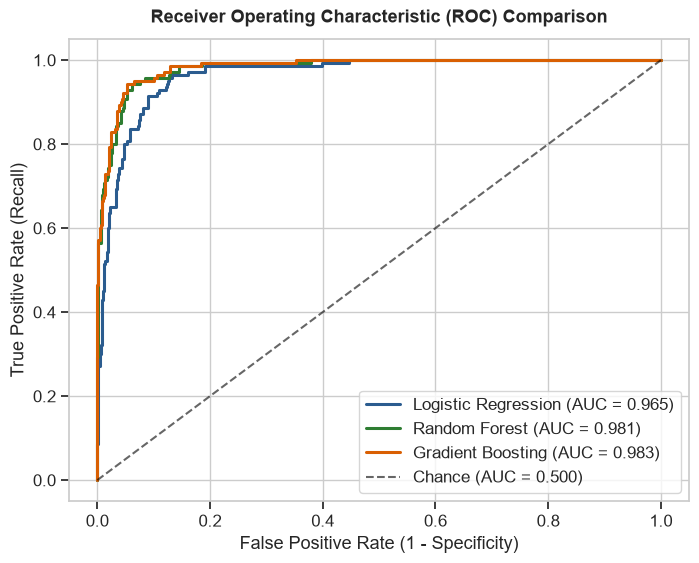

In [11]:
# ROC Curves Comparison
plt.figure(figsize=(8, 6))
colors = {'Logistic Regression': '#2b5c8f', 'Random Forest': '#2e7d32', 'Gradient Boosting': '#d95f02'}

for name, y_prob in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', color=colors[name], linewidth=2.2)

plt.plot([0, 1], [0, 1], 'k--', label='Chance (AUC = 0.500)', alpha=0.6)
plt.title('Receiver Operating Characteristic (ROC) Comparison', fontweight='bold', pad=12)
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right', frameon=True)
plt.show()

## 7. 🔍 Feature Importance & Churn Drivers
Analyzing top predictors using Random Forest Gini Importance and Logistic Regression Log-Odds coefficients.

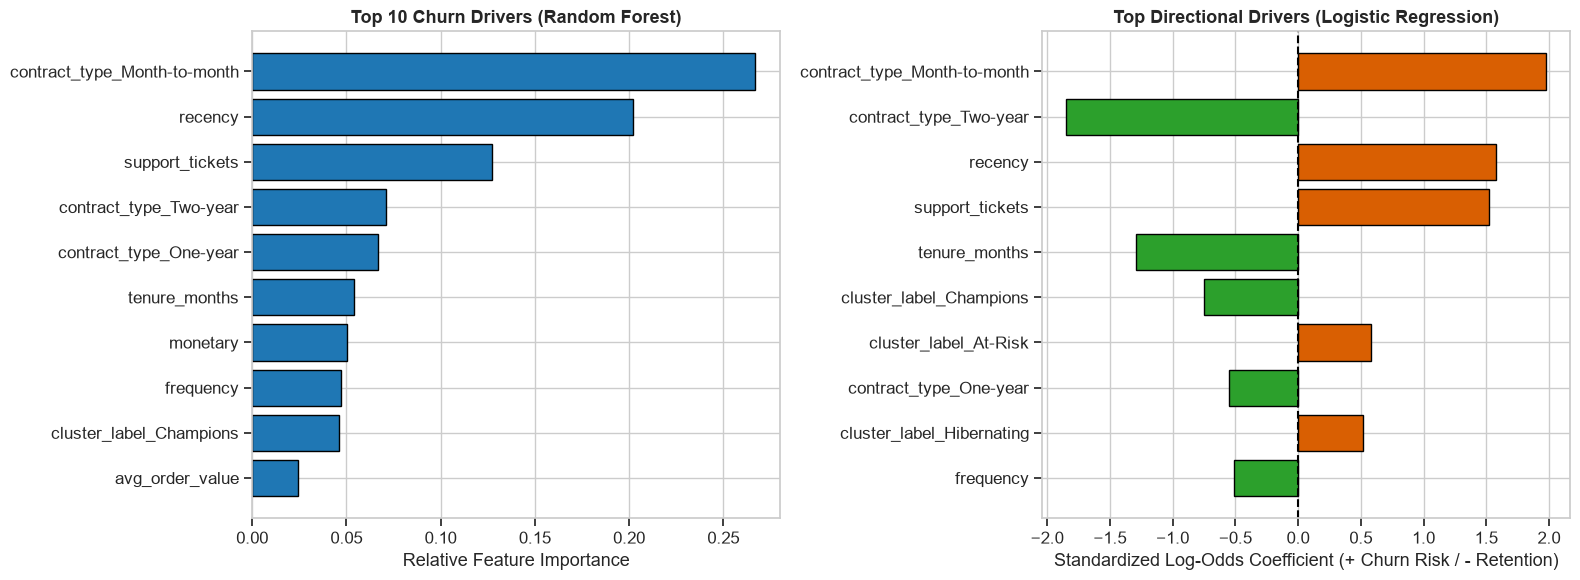

In [12]:
rf_clf = models['Random Forest'][0]
lr_clf = models['Logistic Regression'][0]

fi_df = pd.DataFrame({'Feature': X.columns, 'Importance': rf_clf.feature_importances_})
fi_df = fi_df.sort_values(by='Importance', ascending=True)

lr_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': lr_clf.coef_[0]})
lr_df['Abs'] = lr_df['Coefficient'].abs()
lr_df = lr_df.sort_values(by='Abs', ascending=True).tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Random Forest MDI
axes[0].barh(fi_df.tail(10)['Feature'], fi_df.tail(10)['Importance'], color='#1f77b4', edgecolor='black')
axes[0].set_title('Top 10 Churn Drivers (Random Forest)', fontweight='bold')
axes[0].set_xlabel('Relative Feature Importance')

# Logistic Regression Coefficients
colors_lr = ['#d95f02' if c > 0 else '#2ca02c' for c in lr_df['Coefficient']]
axes[1].barh(lr_df['Feature'], lr_df['Coefficient'], color=colors_lr, edgecolor='black')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title('Top Directional Drivers (Logistic Regression)', fontweight='bold')
axes[1].set_xlabel('Standardized Log-Odds Coefficient (+ Churn Risk / - Retention)')

plt.tight_layout()
plt.show()

## 8. 📋 Strategic Business Playbook & Retention Recommendations

| Customer Segment | Churn Risk | Retention Strategy & Actionable Tactics |
| :--- | :--- | :--- |
| **Champions** | **Very Low (<5%)** | **VIP Treatment & Advocacy:** Invite to early feature previews, loyalty tier bonuses, and referral incentives. Protect with priority customer success routing. |
| **Loyal Customers** | **Low (~10%)** | **Upsell & Contract Migration:** Incentivize upgrading from Month-to-Month contracts to discounted 1-Year or 2-Year subscriptions to lock in long-term retention. |
| **At-Risk** | **High (~30%)** | **Proactive Re-engagement:** Trigger automated win-back campaigns at Day 45-60 of inactivity with time-sensitive promotional vouchers and product recommendations. |
| **Hibernating** | **Critical (>40%)** | **Automated Reactivation or Sunsetting:** Run lightweight drip discount campaigns. If unengaged for >180 days, deprioritize marketing spend to conserve budget. |

### Operational Guardrails:
- **Support Intervention Threshold:** Trigger an immediate manager reach-out when a customer reaches **3 support tickets within a 60-day window** to prevent avoidable churn.
- **Automated Model Inference:** Run daily batch scoring with the Gradient Boosting classifier to route high churn-probability accounts ($P > 0.60$) directly to the Customer Success retention team.